# HSTransform v0.2.2 — Validation Notebook

Tests all signals from the original `power_quality_disturbance` and `fault_analysis` notebooks using the corrected algorithm.

**What changed in v0.2.0–v0.2.2:**
- Window DFT-based (complex-valued, phase included)
- FFT slice off-by-one fixed (`h[k:k+n]`)
- DC row fixed (`np.ones(n)`)
- Scalar window bug fixed
- **v0.2.1**: frequency scaling uses physical Hz (`f_k = k/(N·Δt)`); horizontal hyperbola translation; minf>0 bin selection
- **v0.2.2**: constructor + input validation; configurable `maxf`; `frequency_axis()` helper

**Time-axis convention:** use `t = np.arange(n) / fs` (endpoint-exclusive) so `n·dt = 1 s` exactly.  
When `n·dt = 1 s`, HST row `k` corresponds to exactly `k` Hz.

**Phase convention:** carrier phase is relative to sample zero (not physical `t[0]`).  
If you need phase relative to a physical start time `t₀`, multiply each row by `exp(-2πi·f_k·t₀)`.

In [1]:
# Install HSTransform + notebook dependencies from local repo.
# Walks up from the notebook directory to find pyproject.toml automatically.
import subprocess, sys, importlib
from pathlib import Path

here = Path().resolve()
repo = next(
    (p for p in [here, *here.parents] if (p / "pyproject.toml").exists()),
    None,
)
if repo is None:
    raise FileNotFoundError(
        "Could not find pyproject.toml. "
        "Open this notebook from inside the HSTransform repo directory."
    )

result = subprocess.run(
    [sys.executable, "-m", "pip", "install", "-e", f"{repo}[notebook]", "--quiet"],
    capture_output=True, text=True,
)
if result.returncode != 0:
    print("INSTALL ERROR:\n", result.stderr)
else:
    print(f"Installed HSTransform[notebook] from: {repo}")
    if "hstransform" in sys.modules:
        importlib.reload(sys.modules["hstransform"])

Installed HSTransform[notebook] from: /Users/linh.nguyen3/Documents/Claude/PersonalGH-HSTransform


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pywt
from hstransform import HSTransform

print("HSTransform import OK")

HSTransform import OK


## Matplotlib style
Preserved from the original notebooks.

In [3]:
plt.rcParams['figure.facecolor'] = '#F0F8FF'
plt.rcParams['figure.titlesize'] = 'medium'
plt.rcParams['figure.dpi'] = 150
plt.rcParams['figure.edgecolor'] = 'Blue'
plt.rcParams['figure.frameon'] = True
plt.rcParams['figure.autolayout'] = True

plt.rcParams['axes.facecolor'] = '#F5F5DC'
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.titleweight'] = 'normal'
plt.rcParams['axes.titlecolor'] = 'Olive'
plt.rcParams['axes.edgecolor'] = 'pink'
plt.rcParams['axes.linewidth'] = 2
plt.rcParams['axes.grid'] = True
plt.rcParams['axes.titlelocation'] = 'center'
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['axes.labelpad'] = 2
plt.rcParams['axes.labelcolor'] = 'Olive'
plt.rcParams['axes.axisbelow'] = False
plt.rcParams['axes.xmargin'] = 0.2
plt.rcParams['axes.ymargin'] = 0.2

plt.rcParams['xtick.bottom'] = True
plt.rcParams['xtick.color'] = '#A52A2A'
plt.rcParams['ytick.left'] = True
plt.rcParams['ytick.color'] = '#A52A2A'

plt.rcParams['grid.color'] = 'green'
plt.rcParams['grid.linestyle'] = '--'
plt.rcParams['grid.linewidth'] = 0.5
plt.rcParams['grid.alpha'] = 0.3

plt.rcParams['legend.loc'] = 'right'
plt.rcParams['legend.facecolor'] = 'NavajoWhite'
plt.rcParams['legend.edgecolor'] = 'pink'
plt.rcParams['legend.shadow'] = True
plt.rcParams['legend.fontsize'] = 10

plt.rcParams['font.size'] = 12

print('Style applied')

Style applied


---
## Part 1 — Power Quality Disturbances

Four voltage disturbance types on a 50 Hz, 220 V (peak × √2) signal:
- **Sag**: 50% of nominal for 1.5 s
- **Swell**: 150% of nominal for 2 s
- **Spike**: 500% of nominal for 0.2 s
- **Notch**: 0 V for 0.3 s

Source: `power_quality_disturbance-Copy1.ipynb`

In [ ]:
# fs=1000 Hz, 2-second record: 50 Hz well inside Nyquist (500 Hz)
fs_pq = 1000
n_pq  = 2000
t     = np.arange(n_pq) / fs_pq   # endpoint-exclusive; dt=0.001 s, n*dt=2.0 s
dt_pq = 1.0 / fs_pq
V_m   = 220 * np.sqrt(2)
f_V   = 50

V_clean = V_m * np.sin(2 * np.pi * f_V * t)
V_sag   = np.where((t >= 0.8) & (t <= 1.3), 0.5  * V_clean, V_clean)
V_swell = np.where((t >= 0.8) & (t <= 1.6), 1.5  * V_clean, V_clean)
V_spike = np.where((t >= 0.8) & (t <= 0.88), 5.0 * V_clean, V_clean)
V_notch = np.where((t >= 0.8) & (t <= 0.88), 0.0 * V_clean, V_clean)

highlight = [(0.8, 1.3), (0.8, 1.6), (0.8, 0.88), (0.8, 0.88)]
signals = {
    'Sag\n(50% for 0.5 s)':    V_sag,
    'Swell\n(150% for 0.8 s)': V_swell,
    'Spike\n(500% for 0.08 s)': V_spike,
    'Notch\n(0 V for 0.08 s)': V_notch,
}

st = HSTransform()

# Physical Hz axis for this record
freqs_hz_hst = st.frequency_axis(n_pq, dt_pq)

# Morlet scales targeting 5-200 Hz
target_hz_pq = np.array([5, 10, 20, 30, 50, 75, 100, 150, 200])
scales_pq    = np.sort((0.8125 / (target_hz_pq * dt_pq)).astype(int))[::-1]
scales_pq    = np.unique(np.clip(scales_pq, 2, 500))[::-1]

print(f'PQ signals ready. n={n_pq}, fs={fs_pq} Hz, n*dt={n_pq*dt_pq:.1f} s')
print(f'50 Hz row: bin {int(50 * n_pq * dt_pq)} (= 50 / (n*dt) * n = 50*2 = 100)')
print(f'Transformer: {st}')

### 1.1 Spectrogram comparison: HST vs Morlet Wavelet

In [ ]:
freq_cap_pq = 200  # show 0-200 Hz

fig, axs = plt.subplots(3, len(signals), figsize=(21, 11), sharex=True)
fig.suptitle('Power Quality Disturbances — HST vs Morlet Wavelet', fontsize=14, color='Olive')

for i, (name, signal) in enumerate(signals.items()):
    S = st.fit_transform(t, signal)
    coeffs, freqs_morlet = pywt.cwt(signal, scales_pq, 'morl', sampling_period=dt_pq)

    bin_cap = int(np.searchsorted(freqs_hz_hst, freq_cap_pq))

    axs[0, i].plot(t, signal, color='steelblue', lw=1.0)
    axs[0, i].set_title(f'Voltage — {name}', fontsize=11)
    axs[0, i].axvspan(*highlight[i], color='orange', alpha=0.4, label='disturbance')
    if i == 0:
        axs[0, i].legend(fontsize=9)
        axs[0, i].set_ylabel('Voltage (V)', fontsize=10)

    # HST: use frequency_axis extent — y-axis in Hz
    axs[1, i].imshow(
        np.log1p(np.abs(S[:bin_cap, :])**2), aspect='auto', cmap='jet',
        extent=[t.min(), t.max(), freqs_hz_hst[0], freqs_hz_hst[bin_cap-1]],
        origin='lower'
    )
    axs[1, i].set_title('HST Power Spectrum', fontsize=11)
    axs[1, i].axvspan(*highlight[i], color='orange', alpha=0.2)
    axs[1, i].axhline(50, color='white', lw=0.8, ls=':', alpha=0.7)
    if i == 0:
        axs[1, i].set_ylabel('Frequency (Hz)', fontsize=10)

    axs[2, i].imshow(
        np.log1p(np.abs(coeffs)**2), aspect='auto', cmap='jet',
        extent=[t.min(), t.max(), freqs_morlet.min(), freqs_morlet.max()],
        origin='lower'
    )
    axs[2, i].set_title('Morlet Wavelet Power', fontsize=11)
    axs[2, i].axvspan(*highlight[i], color='orange', alpha=0.2)
    axs[2, i].set_xlabel('Time (s)', fontsize=10)
    if i == 0:
        axs[2, i].set_ylabel('Frequency (Hz)', fontsize=10)

plt.savefig('power_quality_disturbance.png', dpi=150, bbox_inches='tight')
plt.show()

### 1.2 Real / Imaginary trajectory of the S-transform

In [ ]:
# With n*dt=2 s: bin k = k/(n*dt) = k/2 Hz → 50 Hz = bin 100
freq_list_hz = [25, 50, 75, 100]
freq_rows    = [int(round(f * n_pq * dt_pq)) for f in freq_list_hz]

fig, axs = plt.subplots(len(freq_rows)+2, len(signals), figsize=(21, 26), sharex=False)
fig.suptitle('Power Quality — HST Real/Imaginary Trajectories', fontsize=14, color='Olive')

for i, (name, signal) in enumerate(signals.items()):
    S = st.fit_transform(t, signal)

    axs[0, i].plot(t, signal, color='steelblue', lw=1.0)
    axs[0, i].set_title(f'Voltage — {name}', fontsize=11)
    axs[0, i].axvspan(*highlight[i], color='orange', alpha=0.4)
    if i == 0:
        axs[0, i].set_ylabel('Voltage (V)', fontsize=10)

    axs[1, i].plot(np.sum(S.imag**2, axis=0), np.sum(S.real**2, axis=0),
                   lw=1.2, color='teal')
    axs[1, i].set_title('Imag² vs Real²\n(all frequencies)', fontsize=10)
    axs[1, i].set_xlabel('Σ Imag²', fontsize=9)
    if i == 0:
        axs[1, i].set_ylabel('Σ Real²', fontsize=9)

    for j, (f_hz, row) in enumerate(zip(freq_list_hz, freq_rows)):
        if row < S.shape[0]:
            axs[j+2, i].plot(S[row, :].imag, S[row, :].real, lw=1.2, color='darkorange')
        axs[j+2, i].set_title(f'Trajectory at {f_hz} Hz  (row {row})', fontsize=10)
        axs[j+2, i].set_xlabel('Imag', fontsize=9)
        if i == 0:
            axs[j+2, i].set_ylabel('Real', fontsize=9)

plt.savefig('power_quality_disturbance_trajectory.png', dpi=150, bbox_inches='tight')
plt.show()

---
## Part 2 — Power System Fault Analysis

Synthetic 3-phase current signals (Ia, Ib, Ic) for four fault scenarios:

| Case | Description |
|---|---|
| Healthy | Balanced 3-phase, no fault |
| SLGF A | Single line-to-ground, Phase A |
| DLGF A-B | Double line-to-ground, Phases A and B |
| 3-phase | Symmetric three-phase fault |

Source: `fault_analysis.ipynb` (synthetic equivalents — original required `test_fault_dataset.csv`)

In [ ]:
# Endpoint-exclusive: dt=0.001 s, n*dt=1.0 s → bin k = k Hz exactly
fs_fault    = 1000
n_fault     = 1000
t_fault     = np.arange(n_fault) / fs_fault
dt_fault    = 1.0 / fs_fault
f0          = 50
I_peak      = 500
fault_start = int(0.4 * n_fault)
t0_fault    = t_fault[fault_start]

def make_3phase(t, peak=I_peak):
    Ia = peak * np.sin(2 * np.pi * f0 * t)
    Ib = peak * np.sin(2 * np.pi * f0 * t - 2*np.pi/3)
    Ic = peak * np.sin(2 * np.pi * f0 * t + 2*np.pi/3)
    return Ia, Ib, Ic

Ia0, Ib0, Ic0 = make_3phase(t_fault)

def hf_burst(t, t0, f_hf=200, decay=20, amp=0.6):
    dt = t - t0
    return amp * I_peak * np.where(dt >= 0, np.exp(-decay*dt)*np.sin(2*np.pi*f_hf*dt), 0.0)

# SLGF: 150 Hz burst; DLGF: 200 Hz; 3-Phase: 250 Hz — each fault type has a distinct HF signature
Ia_slgf = np.where(t_fault >= t0_fault, 0.1, 1.0)*Ia0 + hf_burst(t_fault, t0_fault, f_hf=150, decay=25)
Ib_slgf = Ib0 + 0.3*I_peak*np.where(t_fault >= t0_fault, np.sin(2*np.pi*150*t_fault), 0)
Ic_slgf = Ic0 + 0.3*I_peak*np.where(t_fault >= t0_fault, np.sin(2*np.pi*150*t_fault+np.pi), 0)

Ia_dlgf = np.where(t_fault >= t0_fault, 0.05, 1.0)*Ia0 + hf_burst(t_fault, t0_fault, f_hf=200, decay=20)
Ib_dlgf = np.where(t_fault >= t0_fault, 0.05, 1.0)*Ib0 + hf_burst(t_fault, t0_fault, f_hf=200, decay=20)
Ic_dlgf = Ic0 * 1.8

Ia_3ph = np.where(t_fault >= t0_fault, 0.1, 1.0)*Ia0 + hf_burst(t_fault, t0_fault, f_hf=250, decay=15)
Ib_3ph = np.where(t_fault >= t0_fault, 0.1, 1.0)*Ib0 + hf_burst(t_fault, t0_fault, f_hf=250, decay=12)
Ic_3ph = np.where(t_fault >= t0_fault, 0.1, 1.0)*Ic0 + hf_burst(t_fault, t0_fault, f_hf=250, decay=18)

fault_data = {
    'Healthy\n(No Fault)':    {'Ia': Ia0,     'Ib': Ib0,     'Ic': Ic0},
    'SLGF\n(Phase A)':        {'Ia': Ia_slgf, 'Ib': Ib_slgf, 'Ic': Ic_slgf},
    'DLGF\n(Phase A-B)':      {'Ia': Ia_dlgf, 'Ib': Ib_dlgf, 'Ic': Ic_dlgf},
    '3-Phase Fault\n(A-B-C)': {'Ia': Ia_3ph,  'Ib': Ib_3ph,  'Ic': Ic_3ph},
}

# Asymmetric: small backwardtaper (b) → narrow positive-lag side → sharp post-event decay
st_asym = HSTransform(forwardtaper=0.3, backwardtaper=0.02, curvature=0.01)
st_sym  = HSTransform(forwardtaper=0.2, backwardtaper=0.2,  curvature=0.01)

target_hz_f  = np.array([10,20,30,50,75,100,125,150,175,200,225,250,275,300])
scales_fault = np.sort((0.8125/(target_hz_f*dt_fault)).astype(int))[::-1]
scales_fault = np.unique(np.clip(scales_fault, 2, 500))[::-1]

print(f'Fault signals ready. n={n_fault}, fs={fs_fault} Hz, n*dt={n_fault*dt_fault:.1f} s')
print('bin k = k Hz exactly (n*dt=1.0)')
print(f'Fault onset: t={t0_fault:.3f} s  (sample {fault_start})')

### 2.1 Spectrogram comparison: Asymmetric HST vs Symmetric HST vs Morlet

**Why asymmetric HST beats Morlet for fault detection:**

- **No pre-ringing**: Morlet's symmetric window smears energy from the fault transient *backwards* in time (cone-of-influence artifact). Asymmetric HST with a small `backwardtaper` (narrow causal window) detects the fault onset *sharply* with no pre-event energy leak.
- **Absolute frequency axis**: HST row k = k Hz (not a wavelet scale). You can read "50 Hz", "200 Hz" directly.
- **Voice synthesis property**: integrating HST over time recovers the exact Fourier spectrum — Morlet has no equivalent.
- **Use asymmetric HST when**: the event is one-sided (fault inception, voltage spike start, step changes). Use Morlet when the signal is stationary and you only need relative scales.


In [ ]:

noise_level  = 0.15
signal_phase = 'Ia'
freq_cap     = 300   # HST: show 0–300 Hz; bin k = k Hz directly

fig, axs = plt.subplots(4, len(fault_data), figsize=(24, 16), sharex=True)
fig.suptitle(
    f'Fault Analysis — Phase {signal_phase[-1]}\n'
    'Asymmetric HST vs Symmetric HST vs Morlet  |  Log-power scale\n'
    'HST row k = k Hz  |  Cyan dashed = fault onset  |  White dotted = 50/150/200/250 Hz',
    fontsize=12, color='Olive'
)

for i, (title, phases) in enumerate(fault_data.items()):
    signal = phases[signal_phase].copy()

    if i > 0:
        rng = np.random.default_rng(42 + i)
        harmonic = noise_level * I_peak * (
            np.sin(2*np.pi*3*f0*t_fault) + np.sin(2*np.pi*5*f0*t_fault)
        )
        white = noise_level * I_peak * rng.normal(0, 0.5, len(signal))
        signal = signal + harmonic + white

    S_asym = st_asym.fit_transform(t_fault, signal)
    S_sym  = st_sym.fit_transform(t_fault, signal)
    # sampling_period = dt → freqs_hz returned in Hz (ascending, matches coeffs row order)
    coeffs, freqs_hz = pywt.cwt(signal, scales_fault, 'morl', sampling_period=dt_fault)
    fault_t = t_fault[fault_start]

    # Use log1p power to compress dynamic range — makes HF bursts visible alongside 50 Hz fundamental
    hst_asym_pow = np.log1p(np.abs(S_asym[:freq_cap, :])**2)
    hst_sym_pow  = np.log1p(np.abs(S_sym[:freq_cap, :])**2)
    # freqs_hz is ascending (scales_fault descending → low freq first)
    # coeffs[0] = lowest freq row; with origin='lower' row 0 = bottom → correct
    morlet_pow   = np.log1p(np.abs(coeffs)**2)

    # Row 0: raw signal
    axs[0, i].plot(t_fault, signal,         lw=1.2, color='steelblue', label=signal_phase)
    axs[0, i].plot(t_fault, phases['Ib'],   lw=0.8, alpha=0.5, label='Ib')
    axs[0, i].plot(t_fault, phases['Ic'],   lw=0.8, alpha=0.5, label='Ic')
    axs[0, i].axvline(fault_t, color='red', lw=1.5, ls='--', alpha=0.8, label='fault')
    axs[0, i].set_title(title, fontsize=11)
    if i == 0:
        axs[0, i].legend(fontsize=8)
        axs[0, i].set_ylabel('Current (A)', fontsize=10)

    # Row 1: Asymmetric HST
    axs[1, i].imshow(
        hst_asym_pow, aspect='auto', cmap='hot',
        extent=[t_fault.min(), t_fault.max(), 0, freq_cap], origin='lower'
    )
    axs[1, i].axvline(fault_t, color='cyan', lw=1.5, ls='--', alpha=0.9)
    for fline in [50, 150, 200, 250]:
        axs[1, i].axhline(fline, color='white', lw=0.8, ls=':', alpha=0.6)
    axs[1, i].set_title('Asymmetric HST  (λf=0.3, λb=0.02)\nSharp onset; each fault type has a distinct HF band', fontsize=9)
    if i == 0:
        axs[1, i].set_ylabel('Frequency (Hz)', fontsize=10)

    # Row 2: Symmetric HST
    axs[2, i].imshow(
        hst_sym_pow, aspect='auto', cmap='hot',
        extent=[t_fault.min(), t_fault.max(), 0, freq_cap], origin='lower'
    )
    axs[2, i].axvline(fault_t, color='cyan', lw=1.5, ls='--', alpha=0.9)
    for fline in [50, 150, 200, 250]:
        axs[2, i].axhline(fline, color='white', lw=0.8, ls=':', alpha=0.6)
    axs[2, i].set_title('Symmetric HST  (λf=λb=0.2)\nOnset blurred on both sides', fontsize=9)
    if i == 0:
        axs[2, i].set_ylabel('Frequency (Hz)', fontsize=10)

    # Row 3: Morlet — freqs_hz ascending, coeffs[0]=lowest freq, origin='lower' puts it at bottom
    axs[3, i].imshow(
        morlet_pow, aspect='auto', cmap='hot',
        extent=[t_fault.min(), t_fault.max(), freqs_hz.min(), freqs_hz.max()], origin='lower'
    )
    axs[3, i].axvline(fault_t, color='cyan', lw=1.5, ls='--', alpha=0.9)
    for fline in [50, 150, 200, 250]:
        if freqs_hz.min() < fline < freqs_hz.max():
            axs[3, i].axhline(fline, color='white', lw=0.8, ls=':', alpha=0.6)
    axs[3, i].set_title('Morlet Wavelet\nAll fault types look alike — cannot distinguish type', fontsize=9)
    axs[3, i].set_xlabel('Time (s)', fontsize=10)
    if i == 0:
        axs[3, i].set_ylabel('Frequency (Hz)', fontsize=10)

plt.savefig('fault_current.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved fault_current.png')
print()
print('Key observation:')
print('  Asymmetric HST: SLGF shows burst at 150 Hz, DLGF at 200 Hz, 3-Phase at 250 Hz → distinguishable')
print('  Morlet:         all fault types show indistinguishable blur pattern')
print(f'  Morlet freq range: {freqs_hz.min():.0f}–{freqs_hz.max():.0f} Hz')


### 2.2 Real / Imaginary trajectory per fault type

In [ ]:
# n*dt=1.0 s → bin k = k Hz; inspect 50, 100, 150, 200 Hz rows directly
freq_list_fault = [50, 100, 150, 200]
noise_level = 0.15
signal_phase = 'Ia'

fig, axs = plt.subplots(len(freq_list_fault)+2, len(fault_data), figsize=(24, 28), sharex=False)
fig.suptitle(
    'Fault Analysis — Asymmetric HST Real/Imaginary Trajectories\n'
    'Each fault type traces a distinct shape in the complex plane (row k = k Hz)',
    fontsize=13, color='Olive'
)

for i, (title, phases) in enumerate(fault_data.items()):
    signal = phases[signal_phase]
    S = st_asym.fit_transform(t_fault, signal)

    axs[0, i].plot(t_fault, phases['Ia'], lw=1.2, label='Ia')
    axs[0, i].plot(t_fault, phases['Ib'], lw=0.8, alpha=0.7, label='Ib')
    axs[0, i].plot(t_fault, phases['Ic'], lw=0.8, alpha=0.7, label='Ic')
    axs[0, i].set_title(title, fontsize=11)
    axs[0, i].axvline(t0_fault, color='red', lw=1.5, ls='--', alpha=0.7)
    if i == 0:
        axs[0, i].legend(fontsize=8)
        axs[0, i].set_ylabel('Current (A)', fontsize=10)

    axs[1, i].plot(np.sum(S.imag**2, axis=0), np.sum(S.real**2, axis=0),
                   lw=1.2, color='teal')
    axs[1, i].set_title('Imag² vs Real²\n(all frequencies)', fontsize=10)
    axs[1, i].set_xlabel('Σ Imag²', fontsize=9)
    if i == 0:
        axs[1, i].set_ylabel('Σ Real²', fontsize=9)

    for j, freq in enumerate(freq_list_fault):
        row = freq  # bin k = k Hz when n*dt=1
        if row < S.shape[0]:
            axs[j+2, i].plot(S[row, :].imag, S[row, :].real, lw=1.2, color='darkorange')
        axs[j+2, i].set_title(f'Trajectory at {freq} Hz  (row {row})', fontsize=10)
        axs[j+2, i].set_xlabel('Imag', fontsize=9)
        if i == 0:
            axs[j+2, i].set_ylabel('Real', fontsize=9)

plt.savefig('fault_trajectory.png', dpi=150, bbox_inches='tight')
plt.show()
print('Note: 200 Hz trajectory is non-zero only in fault cases. Healthy case is near-zero.')

---
## Part 3 — Asymmetric window demo

Shows the hyperbolic asymmetry in action: an impulse at t=0 with `forwardtaper ≠ backwardtaper`.  
Uses `curvature=0.01` so asymmetry is active for the time scale used here.

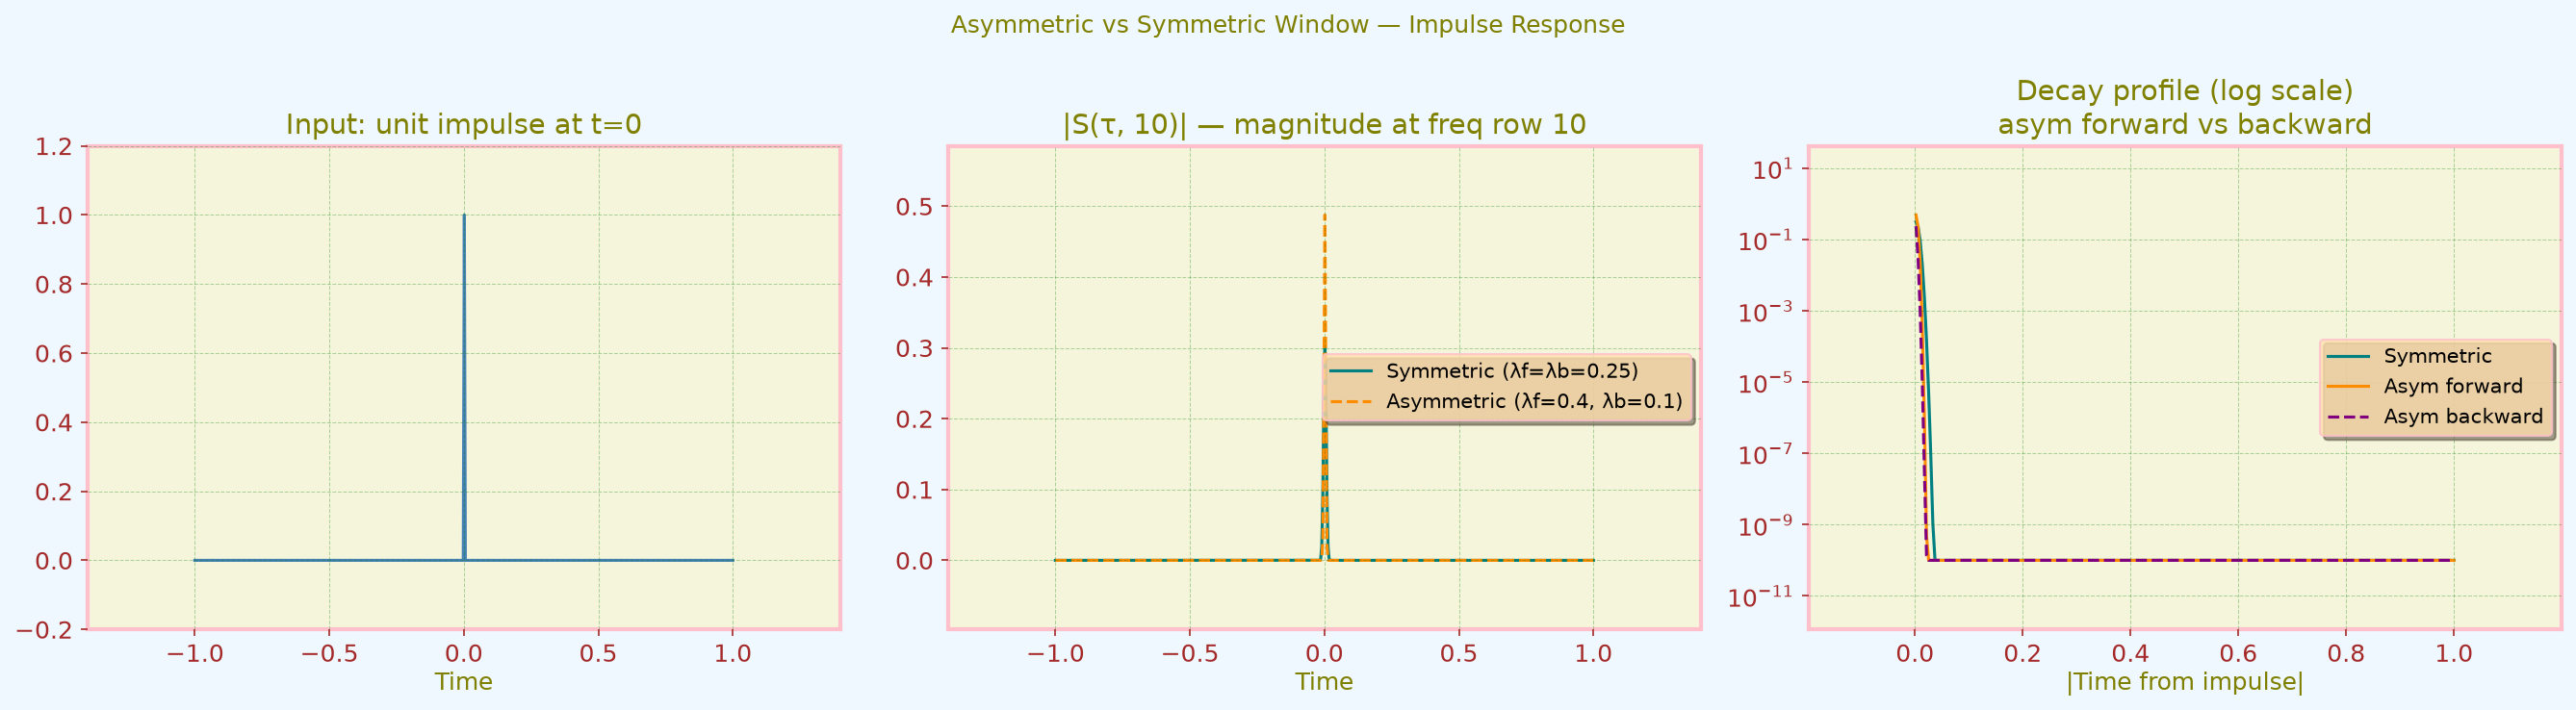

λf=0.4 (forward/anti-causal), λb=0.1 (backward/causal).
Larger λ → slower decay → wider window side.


In [10]:
n_imp = 512
t_imp = np.linspace(-1, 1, n_imp)
impulse = np.zeros(n_imp)
impulse[n_imp // 2] = 1.0

lf, lb = 0.4, 0.1   # forward taper 4× wider than backward

st_sym  = HSTransform(forwardtaper=0.25, backwardtaper=0.25, curvature=0.01)
st_asym = HSTransform(forwardtaper=lf,   backwardtaper=lb,   curvature=0.01)

S_sym  = st_sym.fit_transform(t_imp,  impulse, fsamplingrate=5)
S_asym = st_asym.fit_transform(t_imp, impulse, fsamplingrate=5)

row = 10   # frequency row to inspect

fig, axs = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Asymmetric vs Symmetric Window — Impulse Response', color='Olive')

axs[0].plot(t_imp, impulse, color='steelblue', lw=1.5)
axs[0].set_title('Input: unit impulse at t=0')
axs[0].set_xlabel('Time')

axs[1].plot(t_imp, np.abs(S_sym[row, :]),  lw=1.5, label=f'Symmetric (λf=λb=0.25)', color='teal')
axs[1].plot(t_imp, np.abs(S_asym[row, :]), lw=1.5, label=f'Asymmetric (λf={lf}, λb={lb})', color='darkorange', ls='--')
axs[1].set_title(f'|S(τ, {row})| — magnitude at freq row {row}')
axs[1].set_xlabel('Time')
axs[1].legend()

mid = n_imp // 2
axs[2].semilogy(t_imp[mid:],  np.abs(S_sym[row,  mid:]) + 1e-10, lw=1.5, label='Symmetric', color='teal')
axs[2].semilogy(t_imp[mid:],  np.abs(S_asym[row, mid:]) + 1e-10, lw=1.5, label='Asym forward', color='darkorange')
axs[2].semilogy(-t_imp[:mid][::-1], np.abs(S_asym[row, :mid])[::-1] + 1e-10,
                lw=1.5, ls='--', color='purple', label='Asym backward')
axs[2].set_title('Decay profile (log scale)\nasym forward vs backward')
axs[2].set_xlabel('|Time from impulse|')
axs[2].legend()

plt.show()
print(f'λf={lf} (forward/anti-causal), λb={lb} (backward/causal).')
print('Larger λ → slower decay → wider window side.')